# 01 · The data

**Nakheel Guard** — acoustic early detection of wood-boring insects in trees,
developed toward Red Palm Weevil monitoring in date palms.
SAIF 2026 · Ali Faisal Sadeq Ahmed

This notebook loads the dataset, inspects what is actually in it, explores the
recordings, and extracts the features every later notebook uses.

> **What TreeVibes is, and is not.** TreeVibes records *Xylotrechus chinensis*
> (tiger longicorn beetle), mostly in mulberry trees — **not** Red Palm
> Weevil. The 2026 systematic review of RPW detection calls it *"a
> cross-species wood-borer proxy rather than an RPW-native benchmark"*.
>
> It is still the right dataset to work on: it is the only public in-trunk
> vibration corpus with infestation labels, and it is what Boulila et al.
> (2023) and Karar et al. (2022) evaluate on, so results are comparable.
> But every claim made from it is a claim about **wood-borer detection
> methodology**, not about RPW. Say so on the poster and when a judge asks.

In [1]:
!pip install --upgrade "numpy>=2"

In [2]:
pip install --upgrade soundfile

Note: you may need to restart the kernel to use updated packages.


In [3]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent          # the nakheel-guard folder
for sub in ("src", "scripts"):
    sys.path.insert(0, str(ROOT / sub))

# These imports are wrapped because the most common way they fail on Anaconda
# produces an error that never mentions the real cause. Installing an audio
# library with pip can upgrade NumPy past 2.0, and Anaconda's pre-compiled
# matplotlib / scipy / pandas were built against NumPy 1.x -- so the failure
# surfaces as "initialization failed" deep inside matplotlib's import chain,
# with no hint that NumPy is responsible.
try:
    import numpy as np, pandas as pd, matplotlib.pyplot as plt
except ImportError as _exc:
    _numpy_version = "unknown"
    try:
        import numpy as _np_probe
        _numpy_version = _np_probe.__version__
    except Exception:
        pass
    raise ImportError(f"""Core imports failed. NumPy version: {_numpy_version}

This is almost always a mixed environment: some packages were built for
NumPy 1.x and others require NumPy 2.x, so no single NumPy version satisfies
everything. Typical symptoms are "module compiled using NumPy 1.x cannot be
run in NumPy 2" or "module 'numpy' has no attribute 'long'".

Pinning NumPy does NOT fix this -- in a genuinely mixed environment each pin
only moves the failure to a different package. Build a clean environment:

    conda create -n nakheel python=3.11 -y
    conda activate nakheel
    pip install -r requirements.txt
    pip install jupyterlab ipykernel
    python -m ipykernel install --user --name nakheel --display-name "Python (nakheel)"

then start Jupyter from that prompt and choose
Kernel -> Change Kernel -> Python (nakheel).

If a package is merely missing rather than mismatched, install it into THIS
kernel with:

    import sys
    !"{sys.executable}" -m pip install --upgrade-strategy only-if-needed <package>

Original error: {_exc}
""") from _exc

get_ipython().run_line_magic("matplotlib", "inline")
pd.set_option("display.width", 130)
pd.set_option("display.max_columns", 40)

In [4]:
# ---------------------------------------------------------------- packages
# Check the packages this project needs are importable *in the Python that is
# running this notebook*. On Anaconda, `pip` on the command line often points
# at a different environment than Jupyter uses, which is a common and
# confusing source of "but I installed it" failures.
_missing = []
for _mod, _pkg in [("numpy", "numpy"), ("pandas", "pandas"),
                   ("sklearn", "scikit-learn"), ("scipy", "scipy"),
                   ("librosa", "librosa"), ("soundfile", "soundfile"),
                   ("joblib", "joblib"), ("matplotlib", "matplotlib"),
                   ("openpyxl", "openpyxl")]:
    try:
        __import__(_mod)
    except ImportError:
        _missing.append(_pkg)

if _missing:
    raise ImportError(f"""Missing packages: {', '.join(_missing)}

Install them into THIS kernel by running the following in a new cell,
then restart the kernel (Kernel -> Restart):

    import sys
    !"{sys.executable}" -m pip install --upgrade-strategy only-if-needed {' '.join(_missing)}

The --upgrade-strategy flag matters: without it pip may upgrade NumPy to
satisfy the new package, which can break other packages compiled against a
different NumPy generation. If that happens, see the README -- the fix is a
clean environment, not a NumPy pin.
""")

print("packages: OK")

# ---------------------------------------------------------------- dataset
# "mock"      - structurally faithful stand-in, synthetic audio. For testing.
# "treevibes" - the real download. Put it in data/treevibes/.
WHICH = "treevibes"

DATASETS = {
    "mock":      ROOT / "data" / "mock_treevibes",
    "treevibes": ROOT / "data" / "treevibes",
}
DATASET = DATASETS[WHICH]
TAG = "mock" if WHICH == "mock" else "treevibes"

# The Kaggle distribution splits into field/ and lab/. Only the field
# recordings describe deployed sensors on real trees -- the lab set is
# controlled-condition material that would both swamp the field data (roughly
# 53,000 clips against 4,000) and mix two very different acoustic regimes
# under one label. The published analyses use the field recordings, so that
# is what this project evaluates on.
if WHICH == "treevibes" and (DATASET / "field").is_dir():
    DATASET = DATASET / "field"
    print("using the field recordings only (lab/ excluded)")

if not DATASET.exists():
    if WHICH == "mock":
        # Imported and called directly rather than run as a subprocess, so a
        # failure arrives as an ordinary traceback naming its cause instead
        # of an opaque "non-zero exit status 1".
        import make_mock_treevibes
        print("building the mock dataset (a few minutes)...")
        make_mock_treevibes.generate(out=DATASET, folders=10, days=110,
                                     per_day=2, seconds=3.0)
    else:
        raise FileNotFoundError(f"""{DATASET} not found.

Download TreeVibes from
    https://www.kaggle.com/datasets/potamitis/treevibes
and extract it into
    {DATASET}
""")
print(f"dataset: {DATASET}  (tag '{TAG}')")

packages: OK
using the field recordings only (lab/ excluded)
dataset: C:\Users\DELL\Downloads\nakheel-final\nakheel-final\data\treevibes\field  (tag 'treevibes')


## 1. Inspect before loading

Never assume a downloaded dataset's structure. This prints the directory
shape, filename metadata, labelling hints and any annotation tables — enough
to see how labels must be assigned.

In [5]:
import treevibes as TV
print(TV.inspect(DATASET))

TreeVibes inspection: C:\Users\DELL\Downloads\nakheel-final\nakheel-final\data\treevibes\field
audio files : 4954
tables      : 0
other       : {'.pkf': 2, '.txt': 1}

Directory structure (audio-bearing folders)
------------------------------------------------------------------------
  field/test/difficult_cases                               15 files
  field/test/folder_26                                     27 files
  field/test/folder_27                                     18 files
  field/test/folder_28                                     20 files
  field/test/folder_29                                     20 files
  field/test/folder_30                                     20 files
  field/test/folder_31                                     20 files
  field/test/folder_32                                    753 files
  field/test/folder_33                                    753 files
  field/test/folder_34                                     23 files
  field/train/clean/folder_10      

### What the filenames carry

TreeVibes filenames encode acquisition metadata:

```
F_20200222172127_4_T14.0
  |              | |
  |              | temperature, °C
  |              index within the folder
  timestamp, yyyymmddhhmmss
```

Two consequences that shape this whole project:

1. **Real time.** Recordings span about six months, so a tree's files can be
   ordered into a genuine monitoring stream. Notebook 04 uses this.
2. **Temperature.** Insect activity is strongly temperature-dependent, and
   that turns out to be a trap for any long-running detector. Also notebook 04.

## 2. Load with explicit label provenance

Labels in TreeVibes are assigned **by folder**, not per file. The loader tries
each possible scheme in turn and records which one produced every label, so
nothing is assigned by accident.

In [6]:
df = TV.load(DATASET)
print()
print(TV.describe(df))

  annotation table: TreeVibes.xlsx (35 folder labels)
  labelled 4939 of 4954 audio files
  15 unlabelled (e.g. field/test/difficult_cases/F_20200218001001_19_T8.6.wav)
  label sources: {'annotation_csv': 4939}
  cross-check vs folder structure: 3285/3285 agree (100.0%)

  recordings        : 4939
  class balance     : clean=2554, infested=2385
  recording groups  : 38
  groups with both classes : 0
  time span         : 2020-02-17 to 2020-07-08  (142 days)
  days per tree     : median 0, max 95
  temperature       : 0.8 to 49.6 C (median 9.6)

  NOTE: no tree is recorded in both states, so the
  within-tree contrast is unavailable. The per-tree
  method falls back to a pooled estimate; say so.


In [7]:
df.head(3)[["group", "label", "timestamp", "temperature_c", "label_source"]]

,group,label,timestamp,temperature_c,label_source
0,field/test/folder_26,infested,2020-05-29 18:08:09,26.4,annotation_csv
1,field/test/folder_26,infested,2020-05-29 18:14:19,24.1,annotation_csv
2,field/test/folder_26,infested,2020-05-29 18:19:19,22.5,annotation_csv


### Read the `groups with both classes` line carefully

If it is **0**, no tree was recorded while healthy *and* while infested. That
is the normal case here, and it constrains what notebook 03 can do: the
within-tree contrast is unavailable, so the shift direction must be estimated
across trees and is partly confounded. The code says so when it happens, and
the limitation belongs on the poster.

## 3. What the recordings look like

C:\Users\DELL\anaconda3\envs\nakheel\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


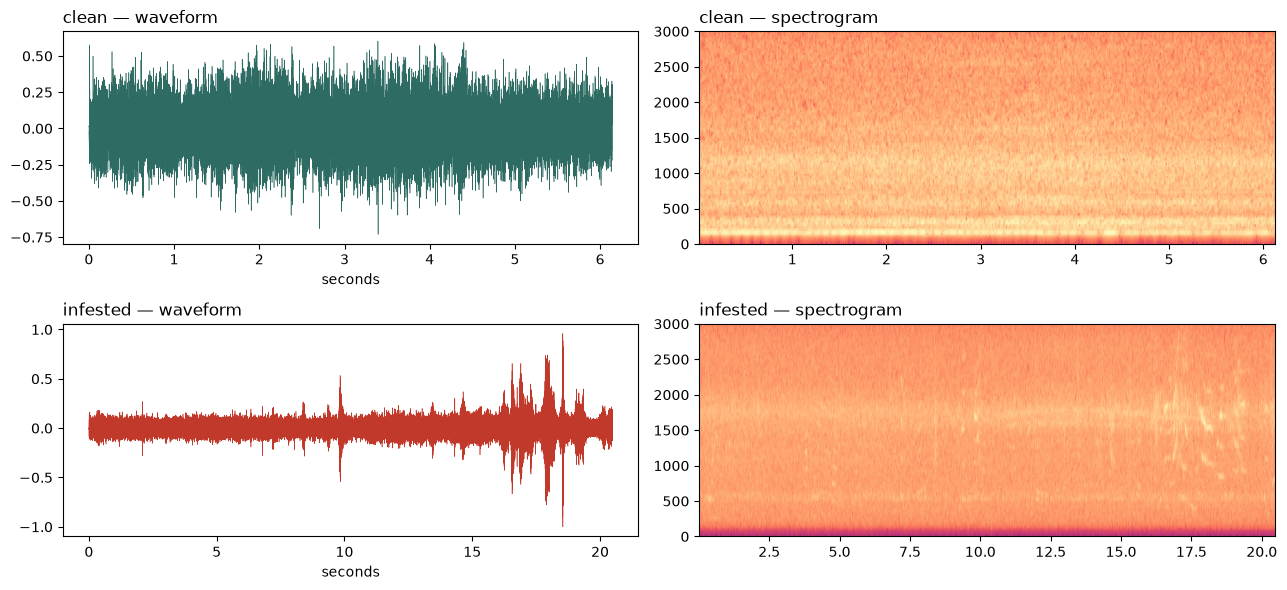

In [8]:
import features as F

clean_path    = df[df.label == "clean"].path.iloc[0]
infested_path = df[df.label == "infested"].path.iloc[0]

fig, axes = plt.subplots(2, 2, figsize=(13, 6))
for row, (path, name, colour) in enumerate(
        [(clean_path, "clean", "#2E6B63"), (infested_path, "infested", "#C0392B")]):
    y = F.load_audio(path)
    axes[row, 0].plot(np.arange(y.size) / F.SAMPLE_RATE, y, lw=0.4, color=colour)
    axes[row, 0].set_title(f"{name} — waveform", loc="left")
    axes[row, 0].set_xlabel("seconds")
    axes[row, 1].specgram(y, Fs=F.SAMPLE_RATE, NFFT=256, noverlap=192, cmap="magma")
    axes[row, 1].set_title(f"{name} — spectrogram", loc="left")
    axes[row, 1].set_ylim(0, 3000)
plt.tight_layout()

In [9]:
from IPython.display import Audio, display
for path, name in [(clean_path, "clean"), (infested_path, "infested")]:
    print(name)
    display(Audio(F.load_audio(path), rate=F.SAMPLE_RATE))

clean


infested


## 4. When were these recorded?

The sampling pattern matters: gaps, uneven coverage and seasonal span all
affect what a longitudinal method can do.

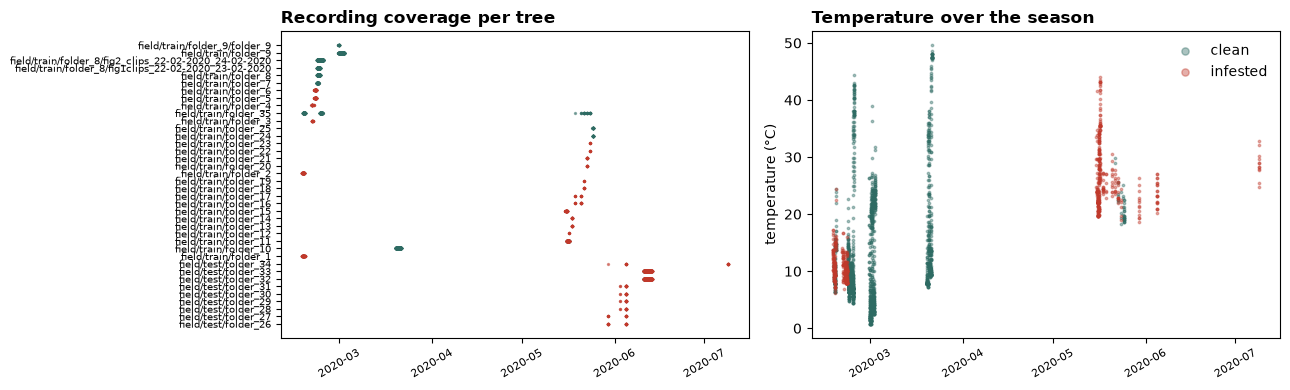

In [10]:
if df["timestamp"].notna().any():
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4))

    for g, sub in df.groupby("group"):
        lab = sub["label"].iloc[0]
        ax1.scatter(sub["timestamp"], [g] * len(sub), s=2, alpha=0.5,
                    color="#C0392B" if lab == "infested" else "#2E6B63")
    ax1.set_title("Recording coverage per tree", loc="left", fontweight="bold")
    ax1.tick_params(axis="x", rotation=30, labelsize=8)
    ax1.tick_params(axis="y", labelsize=7)

    if df["temperature_c"].notna().any():
        for lab, colour in [("clean", "#2E6B63"), ("infested", "#C0392B")]:
            s = df[df.label == lab]
            ax2.scatter(s["timestamp"], s["temperature_c"], s=3, alpha=0.4,
                        color=colour, label=lab)
        ax2.set_ylabel("temperature (°C)")
        ax2.set_title("Temperature over the season", loc="left", fontweight="bold")
        ax2.legend(frameon=False, markerscale=3)
        ax2.tick_params(axis="x", rotation=30, labelsize=8)
    plt.tight_layout()
else:
    print("No timestamps parsed — notebook 04 will not be available.")

## 5. The burst detector

Generic audio features (MFCCs and friends) describe timbre. Feeding activity
is better described by **how often** short impulses occur and **how
irregularly** they are spaced: machinery is regular, a chewing larva is not.
That is what `burst_features` measures, and it is the part of the feature set
that carries the biology.

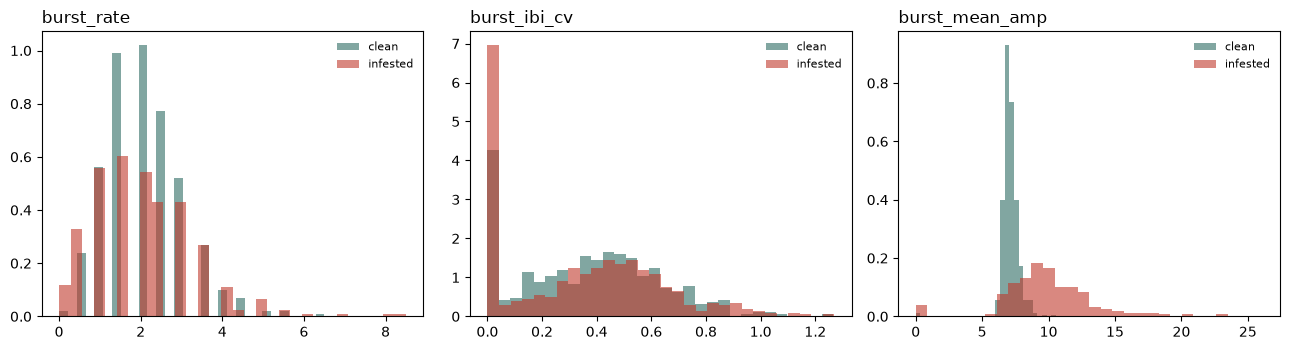

In [11]:
rows = []
for label in ("clean", "infested"):
    for p in df[df.label == label].path.head(25):
        for w in F.frame_windows(F.load_audio(p)):
            rows.append({"label": label, **F.burst_features(w)})
bdf = pd.DataFrame(rows)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, col in zip(axes, ["burst_rate", "burst_ibi_cv", "burst_mean_amp"]):
    for label, colour in [("clean", "#2E6B63"), ("infested", "#C0392B")]:
        ax.hist(bdf[bdf.label == label][col], bins=30, alpha=0.6,
                label=label, color=colour, density=True)
    ax.set_title(col, loc="left")
    ax.legend(frameon=False, fontsize=8)
plt.tight_layout()

## 6. Extract the feature matrix

Every recording is cut into overlapping 2-second windows. Each window becomes
one row, inheriting its recording's label **and** its tree, so windows from one
recording can never straddle a train/test boundary.

TreeVibes is large and lopsided. Set `LIMIT_PER_CLASS` for a first pass —
sampling happens *within* each tree, so no tree is dropped and the grouped
evaluation stays valid.

In [12]:
import extract as E, data as D

LIMIT_PER_CLASS = 1200 if WHICH == "treevibes" else None

work = D.subsample(df, LIMIT_PER_CLASS) if LIMIT_PER_CLASS else df
print(f"extracting from {len(work)} recordings "
      f"across {work['group'].nunique()} trees...")

X, y, groups, clip_ids, names = E.build_matrix(work[["path", "label", "y", "group"]])

# Guard against silent failures: a feature that is constant across the whole
# dataset was never really measured. This check exists because the burst
# detector once returned zero for every recording -- the pipeline ran fine
# and the accuracy looked plausible, and nothing said a whole feature family
# was dead.
check = E.check_features(X, names)
if check["dead_families"]:
    raise RuntimeError(
        f"Dead feature families: {check['dead_families']}. "
        "Fix the extractor before going further.")

E.save_cache(TAG, X, y, groups, clip_ids, names)

work.to_csv(ROOT / "results" / f"manifest_{TAG}.csv", index=False)

print(f"\n{X.shape[0]} windows x {X.shape[1]} features")
print(f"clean={int((y==0).sum())}  infested={int((y==1).sum())}  "
      f"trees={len(set(groups))}")

extracting from 2400 recordings across 38 trees...
    200/2400 clips processed
    400/2400 clips processed
    600/2400 clips processed
    800/2400 clips processed
    1000/2400 clips processed
    1200/2400 clips processed
    1400/2400 clips processed
    1600/2400 clips processed
    1800/2400 clips processed
    2000/2400 clips processed
    2200/2400 clips processed
    2400/2400 clips processed
    F_20200222210800_49_T9.7.ogg: NoBackendError: 
    F_20200222195304_34_T9.1.ogg: NoBackendError: 
    F_20200223195748_22_T9.4.ogg: NoBackendError: 
  feature check: OK (261 features, none degenerate)

38675 windows x 261 features
clean=16192  infested=22483  trees=36


Features and the manifest are cached in `results/`. Continue to
**02 · The leakage experiment**.

In [13]:
import pandas as pd
x = pd.read_excel(ROOT / "data" / "treevibes" / "TreeVibes.xlsx")
print(x.shape)
print(x.columns.tolist())
print()
print(x.head(40).to_string())

(35, 11)
['FOLDER', 'IMEI', 'GPS_LAT', 'GPS_LONG', 'VISUAL', 'AUDIO', 'CONFIRMATION', 'COMMENT', 'Unnamed: 8', 'VISUAL INSPECTION OF TREES EXTERNALLY', 'Unnamed: 10']

       FOLDER          IMEI    GPS_LAT   GPS_LONG VISUAL  AUDIO CONFIRMATION                                                                        COMMENT  Unnamed: 8 VISUAL INSPECTION OF TREES EXTERNALLY                               Unnamed: 10
0    folder_1  8.675840e+14  35.331780  25.129047      B      1          YES                                  bussy city center, pavement, drill bit sensor         NaN                                   NaN                                       NaN
1    folder_2  8.675840e+14  35.331818  25.129067      B      1          YES                                  bussy city center, pavement, drill bit sensor         NaN                                     Α           exit tunnels, heavy infestation
2    folder_3  8.675840e+14  35.331627  25.129084      Α      1           NO            